<a href="https://colab.research.google.com/github/bb38124056/Guild-app/blob/main/ipynb/ex_color_space_skin_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 肌領域の検出（Skin detection）
----

氏名：立石菜奈美

学生番号：38124056

----
基本課題（必須）

    1. カラー画像にはどのような表現がありますか．各表現の利点・欠点を述べてください．

[R, G, B]、[H, S, V]、[C, M, Y] という3次元空間での表現方法がある。<br>

・RGB表現（[R, G, B]）<br>

赤（Red）、緑（Green）、青（Blue）の光の三原色の強さを組み合わせる表現方法。<br>
利点：ディスプレイやデジタルカメラなどの機器で標準的に使われていて、データとして直感的で扱いやすい。<br>
欠点：光の当たり方（照明の明るさ）が変わると、R・G・Bすべての値が大きく変化してしまう。そのため、画像の中から特定の物体や色だけを安定して検出したいときには不便なことがある。<br>

・ HSV表現（[H, S, V]）

色相（Hue：色の種類）、彩度（Saturation：鮮やかさ）、明度（Value：明るさ）の3つの要素で表現する方法。<br>
利点：「照明の違いに頑健な特徴量」として利用できるのが最大の強み。明るさ（V）と色の情報（H, S）が分かれているから、多少光の当たり方が変わっても色相（H）をみれば物体本来の色を捉えやすい。例えば、肌の色の検出はHSV空間の「0 < H < 30°」の範囲を指定するだけで簡単に表現・抽出できる。<br>
欠点：RGBデータからHSVに計算して変換する処理が1ステップ挟まること。彩度が極端に低い場合（黒・白・グレーなどの無彩色）は、色相（H）の値が不安定になりやすいこと。

・CMY表現（[C, M, Y]）
シアン（Cyan）、マゼンタ（Magenta）、イエロー（Yellow）の色の三原色（色材）で表現する方法。<br>
利点：プリンターのインクや印刷物など、光の反射（減衰混色）で色を表す対象に直接対応している。<br>
欠点：画面表示（発光体）などのディスプレイ用の画像処理・特徴抽出にはそのままでは使いづらいこと。


    2. HSV空間にどのような条件を課すと肌領域を検出できますか．
       その条件はどのように見つけられますか．

「色相（H）」「彩度（S）」「明度（V）」3つの要素それぞれに「範囲（下限と上限）」を設けて、すべてを満たす画素を抜き出す条件（AND条件）を課す。<br>
色相（H）の条件：<br>
人の肌の色は、人種や個人差があっても赤〜オレンジに近い系統に集まる性質がある。例えば 0 < H < 30°といった範囲に主に表現される。<br>

彩度（S）と明度（V）の条件：<br>
H（色相）だけで絞り込もうとすると、赤っぽい背景や、極端に白っぽい場所・真っ暗な影まで肌と判定されてしまう。だから、「鮮やかすぎず薄すぎない彩度（S）」や「暗すぎない明るさ（V）」の範囲（例えば S_min < S < S_max かつ V_min < V < V_max）を合わせて条件として指定する必要がある。

条件の見つけ方<br>

1.画像をHSV空間に変換する
実験対象の画像をRGBからHSV色空間に変換する。<br>

2.肌領域のサンプル画素の分布を観察・可視化する<br>

画像の中から「確実に肌だ」と言える領域（手や顔の一部など）の画素値を抜き出してみる。その抜き出した画素のH・S・Vそれぞれの値について、ヒストグラムを描いたり、2次元の散布図（例えばH-S平面など）にプロットしてみる。<br>

こうすることで、特徴空間上で肌の画素が「どの数値の範囲に集中しているか」が視覚的に見えてくる。<br>

3.集中している範囲から閾値（不等式）を決める<br>

可視化したグラフから、肌のデータが収まっている山（分布）の裾野を読み取って、H, S, V それぞれの下限値と上限値を決定する。



4.マスク画像を作って検証・微調整する

決めた条件を満たす画素を1（白）、満たさない画素を0（黒）にした2値画像（マスク画像）を作成して表示する。

背景のノイズが入ってしまう場合は範囲を狭めたり、肌が欠けてしまう場合は範囲を広げるなどして微調整する。


    3. 色だけを用いる肌領域の検出にはどのような問題点がありますか．また，どのような改善の工夫が考えられますか．

問題点<br>
  ・複雑な背景による誤検出（偽陽性エラーの増加）<br>
  現実世界には、家具、衣服、金髪、岩など、人間の肌に非常によく似た色を持つものが無数に存在する。背景の多様性は無限であるため、色情報のみに依存して肌を検知しようとすると、肌ではない背景の領域を肌として誤認する「偽陽性エラー」が頻発するという問題が生じる。 <br>  
  ・多様な変動要因による肌色の激しい変化<br>
  人間の肌の見た目は、多くの要因によって劇的に変化するため、単純な色の基準や固定的なモデルでは正確な検出が極めて難しくなる。具体的な要因には照明の変化、人種の差異、撮影条件、画像モンタージュと複製、メイク、加齢などである。<br>
  ・空間情報の欠如（ピクセル単位の独立処理）<br>
   ピクセル単位の統計的・機械学習的アプローチでは、各画素が単独で（周囲の近傍ピクセルを考慮せずに）分類される。しかし、現実世界のオブジェクトを構成するセグメントは通常、空間的に接続されている。周囲の文脈や空間的関係を無視して色だけに頼ると、セグメンテーション結果に不自然なノイズやアーティファクトが発生しやすくなる。<br>
   ・色空間の次元削減に伴う情報損失の弊害詳細<br>
   多くの従来手法では、照明変動の影響を軽減するという名目で、3次元の色空間（例: RGBなど）から輝度成分を切り離し、色度情報のみの2次元空間（例: RG, HS, CbCr, YIなど）に次元を落として処理が行われてきた。しかし、均一な照明や単一の顔画像、非複雑な背景といった特殊な事前仮定がない限り、低次元空間で色画素を表現するためにカラー情報の一部を単純に切り捨てるアプローチは、新しい複雑な画像に対してシステム全体の精度低下を引き起こす原因となる。<br>

   これらの問題に対する改善の工夫<br>
   ・テクスチャおよびエッジ情報の統合詳細<br>
   色情報だけに頼るのではなく、ピクセル周辺のテクスチャ情報（標準偏差、エントロピー、最大・最小範囲など）やエッジ情報を特徴ベクトルとして組み合わせる手法が取られる。これにより、色合いが肌に似ているだけの背景オブジェクトを効果的に排除し、誤検出率を大幅に下げて検出の信頼性を高めることができる。<br>
   ・マルチ肌色モデル（複数モデルの分割・使い分け）の導入<br>
   あらゆる肌色を1つの単一モデル（単一のクラスタ）で表現しようとすると、モデルを緩くしすぎて背景の誤検出（FP）が増えるか、逆に厳しくしすぎて見落とし（FN）が増えるというトレードオフが生じる。これを解決するため、訓練データを肌色トーン（人種的起源や影、赤みがかった状態など）ごとに異なる複数のクラスターに分割し、「黒っぽい肌モデル」「白っぽい肌モデル」「赤みがかった肌モデル」「明るい肌モデル」などのマルチ肌色モデルを構築して適用する工夫がなされている。<br>
   ・複数色空間のチャンネル融合（マルチ・カラー・スペース・フュージョン）<br>
   単一の色空間の選択にとどまらず、RGB、正規化RGB、YCbCr、CIE $L^*a^*b^*$、HSV、iHSLなど、複数の異なる色空間から多数のカラーチャンネル（例えば19チャンネルなど）を抽出し、それらを融合させるアプローチである。色空間ごとの相関の不完全さを、金融のポートフォリオ理論などを応用した学習ウェイトの最適化によって補うことで、多様な照明や撮像条件に対する頑健性を高め、検出率を向上させることができる。<br>
   ・領域ベースの手法（空間情報・領域拡張・ウォータースレッド）の併用<br>
   ピクセル単位の分類にとどまらず、空間的な連続性を活用する領域ベースのセグメンテーションを組み合わせる。領域拡張（Region growing）: 色とテクスチャに基づいた教師なしセグメンテーションで画像を均質な領域に分割し、種（シード）となる領域から類似する隣接ピクセルへと領域を成長させていくことで、明確なエッジと高い精度の領域抽出を行う。ウォータースレッド法（Watershed segmentation）: 画像の勾配情報（トポグラフィックレリーフ）を利用して catchment basins（集水域）や分割線を求め、ピクセル分類の結果と統合することで、構造化された正確な領域境界を得る工夫がなされる。<br>
   ディープラーニング（畳み込みニューラルネットワーク等）の活用<br>
   近年の新たな方向性として、畳み込みニューラルネットワーク（CNN）などの深層学習技術を肌検知に導入する試みが挙げられる。これにより、従来の手法よりも少ないサンプル数での効率的な学習や、複雑な環境下での高精度な特徴抽出・学習戦略が可能になるとされている。   

HSVは、色を次の3つで表現する方法。
hsv[:,0]	H：色相（色の種類）	0.1未満
hsv[:,1]	S：彩度（色の鮮やかさ）	0.4未満
hsv[:,2]	V：明度（明るさ）	今回は未使用

    4.その他，気づいたこと，調べたことがあれば書いてください．

（ここに回答を書いてください）



----


In [1]:
#@title データセットをダウンロードします．
import zipfile
zipURL = "https://github.com/tsakailab/prml/raw/master/datasets/SkinDataset.zip"
!wget $zipURL --no-check-certificate --show-progress -q -O "/tmp/SkinDataset.zip"
with zipfile.ZipFile("/tmp/SkinDataset.zip", 'r') as f:
    f.extractall("./sample_data")


path_img = "./sample_data/SkinDataset/img"
path_lbl = "./sample_data/SkinDataset/lbl"
print("path_img = \"{}\"".format(path_img))
print("path_lbl = \"{}\"".format(path_lbl))

import os
imgfiles = [f for f in os.listdir(path_img) if os.path.isfile(os.path.join(path_img, f))]
print("imgfiles: list of filenames of " + str(len(imgfiles)) + " images in " + path_img)
lblfiles = [os.path.splitext(os.path.basename(f))[0]+".png" for f in imgfiles]
print("lblfiles: list of filenames of " + str(len(imgfiles)) + " skin masks in " + path_lbl)

import numpy as np
from PIL import Image
def read_images(filenames, path=path_img):
    imgs = []
    for f in filenames:
        img = Image.open(os.path.join(path, f))
        imgs.append(np.asarray(img))
    return imgs

/tmp/SkinDataset.zi 100%[===================>]   5.61M  --.-KB/s    in 0.05s   
path_img = "./sample_data/SkinDataset/img"
path_lbl = "./sample_data/SkinDataset/lbl"
imgfiles: list of filenames of 78 images in ./sample_data/SkinDataset/img
lblfiles: list of filenames of 78 skin masks in ./sample_data/SkinDataset/lbl


### `img_id` で指定した画像と正解の肌領域を表示し，画像のNumpy配列 `img` から画素値 [R, G, B] の3次元ベクトルの集まり `rgb` を作ります．

./sample_data/SkinDataset/img/2007_family.jpg


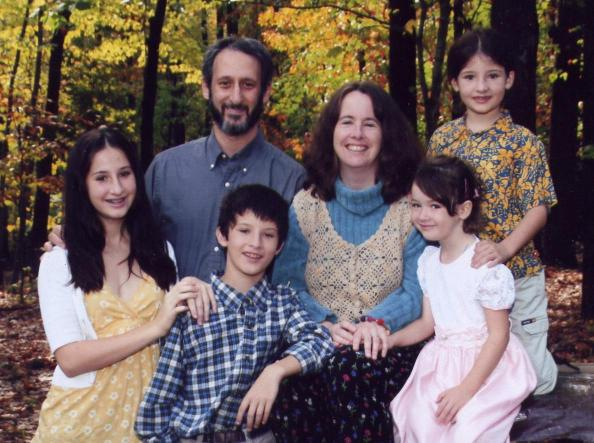

./sample_data/SkinDataset/lbl/2007_family.png


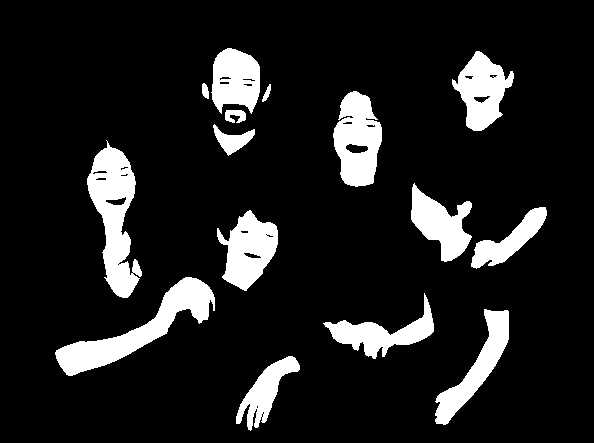

(443, 594, 3)


In [2]:
img_id = 1  # 0..77

import IPython.display as IPd
import os
im = IPd.Image(os.path.join(path_img, imgfiles[img_id]), width=300)
lb = IPd.Image(os.path.join(path_lbl, lblfiles[img_id]), width=300)
print(im.filename)
IPd.display(im)
print(lb.filename)
IPd.display(lb)

img = read_images([ imgfiles[img_id] ], path=path_img)[0]
lbl = read_images([ lblfiles[img_id] ], path=path_lbl)[0]
print(img.shape)

In [3]:
rgb = np.reshape(img, (-1,3))
print("rgb.shape =", rgb.shape)

import pandas as pd
print(pd.DataFrame(data=rgb, columns=["Red", "Green", "Blue"]).head(10))

rgb.shape = (263142, 3)
   Red  Green  Blue
0  196    200   105
1  170    174    77
2  156    156    60
3  152    150    50
4  152    147    47
5  168    159    56
6  192    180    78
7  204    191    87
8  195    178    74
9  178    161    57


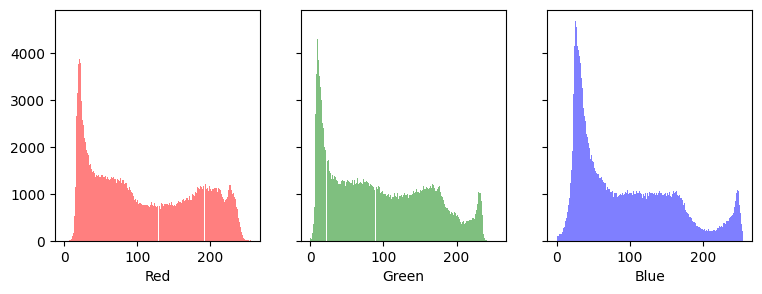

In [4]:
#@title 色のヒストグラムを表示します．
import matplotlib.pyplot as plt

fig, axes = plt.subplots(figsize=(9,3), nrows=1, ncols=3, sharex=True, sharey=True)
axes[0].hist(rgb[:,0], bins = 256, color = 'red', alpha = 0.5)
axes[0].set_xlabel('Red')
axes[1].hist(rgb[:,1], bins = 256, color = 'green', alpha = 0.5)
axes[1].set_xlabel('Green')
axes[2].hist(rgb[:,2], bins = 256, color = 'blue', alpha = 0.5)
axes[2].set_xlabel('Blue')
plt.show()

### RGB色空間で観察します．
- `ns`: 色空間に散布する画素数（画素全部は多すぎるので）．

In [5]:
ns = 3000

n = rgb.shape[0]
ns = min(n, ns)
print("Randomly chosen %d points out of %d points will be displayed." % (ns, n))

Randomly chosen 3000 points out of 263142 points will be displayed.


In [6]:
#@title RGB色空間を表示します．マウスで視点を操作して観察できます．
import plotly.graph_objs  as go
import plotly.graph_objs.layout  as gol

ps = np.random.choice(n, ns, replace=False)
rgbs = rgb[ps] # * 1.5 # brighter

# https://plotly.com/python-api-reference/generated/plotly.graph_objects.Scatter3d.html#plotly.graph_objects.Scatter3d
trace = go.Scatter3d(x=rgbs[:,0], y=rgbs[:,1], z=rgbs[:,2], mode='markers',
                     marker=dict(size=2,
                                color=['rgb({},{},{})'.format(r,g,b) for r,g,b in zip(rgbs[:,0], rgbs[:,1], rgbs[:,2])],
                                opacity=0.8))

layout = go.Layout(margin=dict(l=0,r=0,b=0,t=0), scene=gol.Scene(xaxis=gol.scene.XAxis(title="Red"), yaxis=gol.scene.YAxis(title="Green"), zaxis=gol.scene.ZAxis(title="Blue")))
fig = go.Figure(data=[trace], layout=layout)
camera = dict(up=dict(x=0, y=0, z=1), center=dict(x=0, y=0, z=0), eye=dict(x=1.5, y=1.5, z=0.8))
fig.update_layout(scene_camera=camera)
fig.show()

### ★ [HSV（Hue, Saturation, Value）](https://en.wikipedia.org/wiki/HSL_and_HSV)による表現に変換します．

In [7]:
import matplotlib.colors as colors
hsv = np.reshape(colors.rgb_to_hsv(img/255.0), (-1,3))
print(hsv.shape)

print("hsv.shape =", hsv.shape)

import pandas as pd
print(pd.DataFrame(data=hsv, columns=["Hue", "Saturation", "Value"]).head(10))

(263142, 3)
hsv.shape = (263142, 3)
        Hue  Saturation     Value
0  0.173684    0.475000  0.784314
1  0.173540    0.557471  0.682353
2  0.166667    0.615385  0.611765
3  0.163399    0.671053  0.596078
4  0.158730    0.690789  0.596078
5  0.153274    0.666667  0.658824
6  0.149123    0.593750  0.752941
7  0.148148    0.573529  0.800000
8  0.143251    0.620513  0.764706
9  0.143251    0.679775  0.698039


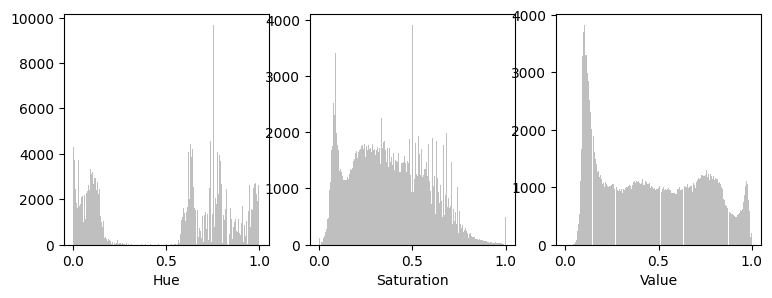

In [8]:
#@title HSVのヒストグラムを表示します．
import matplotlib.pyplot as plt

fig, axes = plt.subplots(figsize=(9,3), nrows=1, ncols=3, sharex=True, sharey=False)
axes[0].hist(hsv[:,0], bins = 256, color = 'gray', alpha = 0.5)
axes[0].set_xlabel('Hue')
axes[1].hist(hsv[:,1], bins = 256, color = 'gray', alpha = 0.5)
axes[1].set_xlabel('Saturation')
axes[2].hist(hsv[:,2], bins = 256, color = 'gray', alpha = 0.5)
axes[2].set_xlabel('Value')
plt.show()

In [9]:
#@title HSV色空間を観察します．マウスで視点を操作して観察できます．
import plotly.graph_objs  as go
import plotly.graph_objs.layout  as gol

nmax = 10000
def ScatterHSV(hsv, rgbs=None):
    if hsv.shape[0] > nmax:
        hsvs = hsv[np.random.choice(hsv.shape[0], nmax, replace=False),:]
    else:
        hsvs = hsv
    if rgbs is None: rgbs = colors.hsv_to_rgb(hsvs) * 255.

    # https://plotly.com/python-api-reference/generated/plotly.graph_objects.Scatter3d.html#plotly.graph_objects.Scatter3d
    trace = go.Scatter3d(x=hsvs[:,0], y=hsvs[:,1], z=hsvs[:,2], mode='markers',
                         marker=dict(size=2,
                                color=['rgb({},{},{})'.format(r,g,b) for r,g,b in zip(rgbs[:,0], rgbs[:,1], rgbs[:,2])],
                                opacity=0.8))
    layout = go.Layout(margin=dict(l=0,r=0,b=0,t=0),
                       scene=gol.Scene(
                           xaxis=gol.scene.XAxis(title="Hue", range=[0,1]),
                           yaxis=gol.scene.YAxis(title="Saturation", range=[0,1]),
                           zaxis=gol.scene.ZAxis(title="Value", range=[0,1])))
    fig = go.Figure(data=[trace], layout=layout)
    camera = dict(up=dict(x=0, y=0, z=1), center=dict(x=0, y=0, z=0), eye=dict(x=1, y=-2, z=0.8))
    fig.update_layout(scene_camera=camera)
    fig.show()

hsvs = hsv[ps]
ScatterHSV(hsvs)

### HSV表現で肌の画素を選び出す方法を考えよう．
- NumPy配列 `hsv` （★のセルを参照）の行が画素に対応します．
- `hsv`の3つの列 Hue，Saturation，Value の値に条件を課してください．条件を満たす画素（`hsv`の行）の番号のNumPy配列を `skin_pos` とします．
    - 例えば，`hsv[:,2] > 0.2` と書くと，Value が 0.2を超える条件を表します．
- 条件を満たす画素の番号の配列は `skin_pos =`[`np.where(条件)[0]`](https://numpy.org/doc/stable/reference/generated/numpy.where.html)のように作成できます．
    - 行についての結果のみを使用するため末尾に`[0]`を付けています．
    - 複数の条件を課すときは，`skin_pos = np.where( logical_and([条件1,条件2,...,条件n]) )[0]`のように書きます．`logical_or`もあります．
    - [for文を書いたら負けかなと思ってる．](https://www.google.com/search?q=python+for+%E8%B2%A0%E3%81%91&rlz=1C1QABZ_jaJP862JP862&sxsrf=ALiCzsb_mbOOWtLLdk8-1feR5u76sZAMxw%3A1665660365256&ei=zfVHY4ioD-_s2roP8aqtiAY&ved=0ahUKEwjIwoyzjN36AhVvtlYBHXFVC2EQ4dUDCA4&uact=5&oq=python+for+%E8%B2%A0%E3%81%91&gs_lcp=Cgdnd3Mtd2l6EAMyBAgAEB46BwgAEB4QogQ6BQgAEKIEOgYIABAHEB5KBAhNGAFKBAhBGABKBAhGGABQAFidCmDADGgAcAF4AIABeYgBgAaSAQMxLjaYAQCgAQHAAQE&sclient=gws-wiz)

In [17]:
from functools import reduce
logical_and = lambda conds: reduce(np.logical_and, conds)
logical_or = lambda conds: reduce(np.logical_or, conds)

skin_pos = np.where( logical_and( [ hsv[:,0] < 0.1, hsv[:,1] < 0.4]) )[0]

print(skin_pos.shape[0], "pixels are selected.")
ScatterHSV(hsv[skin_pos])

44159 pixels are selected.


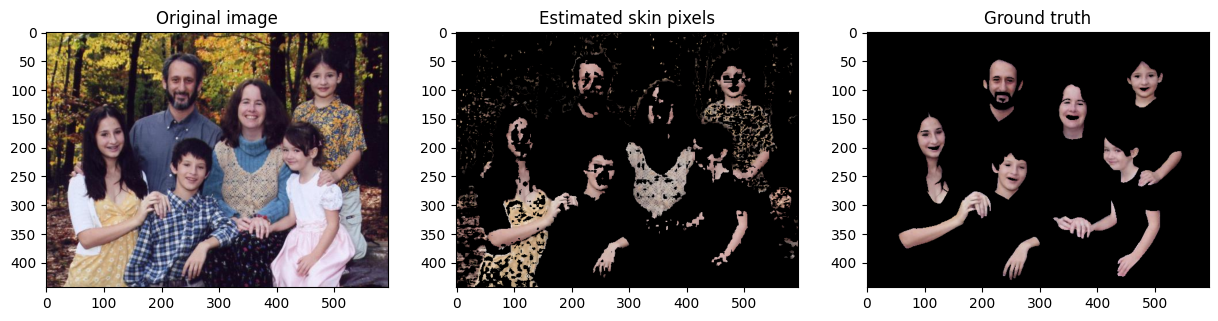

In [18]:
#@title 検出結果を画像で表示します．

#est = np.ones_like(rgb) * 255
est = np.zeros_like(rgb)

est[skin_pos,:] = rgb[skin_pos,:]
est = np.reshape(est, img.shape)

gt = np.zeros_like(img[:,:,:3])
idx_lbl = lbl[:,:,:3] > 0
gt[idx_lbl] = img[:,:,:3][idx_lbl]

plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.imshow(img)
plt.gca().set_title("Original image")
plt.subplot(1,3,2)
plt.imshow(est)
plt.gca().set_title("Estimated skin pixels")
plt.subplot(1,3,3)
plt.imshow(gt)
plt.gca().set_title("Ground truth")
plt.show()

In [19]:
#@title 混同行列（行：正解，列：予測）と評価値
from sklearn import metrics
# https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

y_true = idx_lbl[:,:,0].ravel()
y_pred = np.full_like(y_true, False)
y_pred[skin_pos] = True
cm = metrics.confusion_matrix(y_true, y_pred)
print(cm)

print(metrics.classification_report(y_true, y_pred, labels=[True], target_names=["skin pixels"]))

[[203944  27132]
 [ 15039  17027]]
              precision    recall  f1-score   support

 skin pixels       0.39      0.53      0.45     32066

   micro avg       0.39      0.53      0.45     32066
   macro avg       0.39      0.53      0.45     32066
weighted avg       0.39      0.53      0.45     32066



--------

## 発展課題

畳み込みによる局所特徴の抽出に関する[こちらの教材](https://colab.research.google.com/github/tsakailab/alpp/blob/main/colab/alpp_local_operations.ipynb)に取り組んでください．


- 画像がもつ情報は，局所的な特徴（断片的な形状，模様，配色）の組合せによって表されています．**畳み込み（convolution）** は，画像の **局所特徴（local features）** の量を算出する基本的な演算です．
- カーネルを何種類も用意すれば，エッジや凹凸の断片，色の組合せなど，様々な局所特徴について特徴マップを作成できます．
- ３枚の入力で表せるカラー画像から特徴マップを出力するときと同様に，複数の特徴マップからひとつの特徴マップを作ることもできます．この特徴抽出は，畳み込みニューラルネットワーク（convolutional neural network）の原理となっています．

お疲れさまでした．